# Deborah's Final Single-Cell Generative Modelling Analysis

## Human PBMC single-cell RNA-seq: PCA versus scVI

The pilot run worked. This notebook is the **final portfolio run**.

Run it **from top to bottom without skipping cells**.

### What is improved from the pilot?
- uses the complete PBMC dataset rather than the 3,000-cell test sample;
- makes observation names unique;
- compares 10 PCA dimensions with 10 scVI latent dimensions;
- trains scVI for up to 100 epochs with early stopping;
- uses 5-fold cross-validation for kNN cell-type recovery;
- assesses batch mixing both globally and *within cell types*;
- saves UMAPs, metrics and the training curve.

### Research question
**Does scVI learn a more cell-type-informative representation of human PBMC single-cell RNA-seq data than PCA while retaining good mixing of the two technical batches?**

This wording is deliberately cautious. The pilot showed stronger biological separation with scVI, but did **not** show that scVI reduced batch separation relative to PCA.

## Step 1 — Install packages

In [1]:
%pip install -q "scvi-tools>=1.4,<2" "scanpy>=1.11,<2" "scikit-learn>=1.4" "pandas>=2.1" "matplotlib>=3.8"

print("Installation finished.")

  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.0/45.0 kB 2.9 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.5/79.5 kB 5.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 731.5/731.5 kB 20.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2.2 MB 39.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.8/10.8 MB 38.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 190.2/190.2 kB 7.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 40.6/40.6 kB 1.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 849.3/849.3 kB 24.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 155.3/155.3 kB 7.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.4/983.4 kB 14.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 76.7/76.7 kB 4.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.9/43.9 kB 1.4 MB/s eta 0:00:00
   ━━━

## Step 2 — Imports, reproducibility and GPU check

In [2]:
import os
import random
import zipfile
from pathlib import Path
import importlib.metadata as importlib_metadata

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scanpy as sc
import scvi
import torch

from sklearn.metrics import (
    silhouette_score,
    balanced_accuracy_score,
)
from sklearn.model_selection import StratifiedKFold
from sklearn.neighbors import KNeighborsClassifier

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
scvi.settings.seed = SEED

RESULTS_DIR = Path("results_final")
RESULTS_DIR.mkdir(exist_ok=True)

print("scvi-tools:", scvi.__version__)
print("Scanpy:", importlib_metadata.version("scanpy"))
print("PyTorch:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("No GPU detected. Training will still work, but will be slower.")

INFO: Seed set to 42
INFO:lightning.fabric.utilities.seed:Seed set to 42


scvi-tools: 1.5.1
Scanpy: 1.12.4
PyTorch: 2.11.0+cu130
GPU available: True
GPU: Tesla T4


## Step 3 — Load the complete PBMC dataset

The dataset contains human peripheral blood mononuclear cells from two batches.
It includes gene-expression counts and cell-type annotations.

In [3]:
adata = scvi.data.pbmc_dataset(save_path="data/")
adata.var_names_make_unique()
adata.obs_names_make_unique()

print(adata)
print("\nCell-type counts:")
print(adata.obs["str_labels"].value_counts())

print("\nBatch counts:")
print(adata.obs["batch"].value_counts())

INFO     Downloading file at data/gene_info_pbmc.csv                                                               


Downloading...:   0%|          | 0/908.0 [00:00<?, ?it/s]

INFO     Downloading file at data/pbmc_metadata.pickle                                                             


Downloading...:   0%|          | 0/4000.0 [00:00<?, ?it/s]

INFO     Downloading file at data/pbmc8k/filtered_gene_bc_matrices.tar.gz                                          


...

INFO     Extracting tar file                                                                                       
INFO     Removing extracted data at data/pbmc8k/filtered_gene_bc_matrices                                          
INFO     Downloading file at data/pbmc4k/filtered_gene_bc_matrices.tar.gz                                          


Downloading...:   0%|          | 0/18424.0 [00:00<?, ?it/s]

INFO     Extracting tar file                                                                                       
INFO     Removing extracted data at data/pbmc4k/filtered_gene_bc_matrices                                          


/usr/local/lib/python3.13/dist-packages/scvi/data/_built_in_data/_pbmc.py:77: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  adata = anndata.concat([pbmc8k, pbmc4k], keys=["0", "1"], label="batch")


AnnData object with n_obs × n_vars = 11990 × 3346
    obs: 'n_counts', 'batch', 'labels', 'str_labels'
    var: 'n_counts'
    uns: 'cell_types'
    obsm: 'design', 'raw_qc', 'normalized_qc', 'qc_pc'
    layers: None (.X)

Cell-type counts:
str_labels
CD4 T cells          4996
CD14+ Monocytes      2227
B cells              1621
CD8 T cells          1448
Other                 463
NK cells              457
FCGR3A+ Monocytes     351
Dendritic Cells       339
Megakaryocytes         88
Name: count, dtype: int64

Batch counts:
batch
0    7982
1    4008
Name: count, dtype: int64


## Step 4 — Preserve counts and build the PCA baseline

scVI will use the untransformed count data stored in `adata.layers["counts"]`.

For PCA we use normalised, log-transformed and scaled expression values.

Both representations will use **10 dimensions** for a cleaner comparison.

In [4]:
# Preserve untransformed counts for scVI
adata.layers["counts"] = adata.X.copy()

# Normalise/log-transform for PCA
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)
adata.raw = adata

# Scale and PCA
sc.pp.scale(adata, max_value=10)
sc.tl.pca(adata, n_comps=10, svd_solver="arpack")

print("PCA representation shape:", adata.obsm["X_pca"].shape)

/usr/lib/python3.13/functools.py:934: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)


PCA representation shape: (11990, 10)


## Step 5 — Set up the scVI model

The model uses:
- raw gene counts;
- batch as a technical covariate;
- a 10-dimensional latent space;
- a negative-binomial likelihood.

In [5]:
scvi.model.SCVI.setup_anndata(
    adata,
    layer="counts",
    batch_key="batch",
)

model = scvi.model.SCVI(
    adata,
    n_hidden=128,
    n_latent=10,
    n_layers=2,
    gene_likelihood="nb",
)

print(model)

SCVI model with the following parameters: 
n_hidden: 128, n_latent: 10, n_layers: 2, dropout_rate: 0.1, dispersion: gene, gene_likelihood: nb, 
latent_distribution: normal.
Training status: Not Trained
Model's adata is minified?: False

## Step 6 — Train scVI

The maximum is 100 epochs. Early stopping is enabled.

In [6]:
print("Training scVI on the complete dataset...")

model.train(
    max_epochs=100,
    early_stopping=True,
    check_val_every_n_epoch=5,
    accelerator="auto",
)

print("Training complete.")

INFO: GPU available: True (cuda), used: True
INFO:lightning.pytorch.utilities.rank_zero:GPU available: True (cuda), used: True
INFO: TPU available: False, using: 0 TPU cores
INFO:lightning.pytorch.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO: 💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO:lightning.pytorch.utilities.rank_zero:💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


Training scVI on the complete dataset...


INFO: LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:lightning.pytorch.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.


Training:   0%|          | 0/100 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
INFO: `Trainer.fit` stopped: `max_epochs=100` reached.
INFO:lightning.pytorch.utilities.rank_zero:`Trainer.fit` stopped: `max_epochs=100` reached.


Training complete.


## Step 7 — Extract the scVI latent representation

In [7]:
adata.obsm["X_scVI"] = model.get_latent_representation()

print("scVI latent representation shape:", adata.obsm["X_scVI"].shape)

scVI latent representation shape: (11990, 10)


## Step 8 — Training curve

A steadily improving validation objective without a late deterioration is reassuring.
The curve is a diagnostic, not proof that the biological representation is correct.

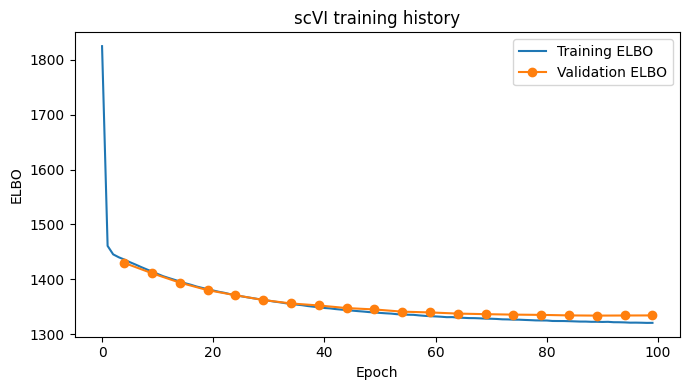

In [8]:
plt.figure(figsize=(7, 4))

if "elbo_train" in model.history:
    train_hist = model.history["elbo_train"]
    plt.plot(
        train_hist.index,
        train_hist.iloc[:, 0],
        label="Training ELBO",
    )

if "elbo_validation" in model.history:
    val_hist = model.history["elbo_validation"]
    plt.plot(
        val_hist.index,
        val_hist.iloc[:, 0],
        label="Validation ELBO",
        marker="o",
    )

plt.xlabel("Epoch")
plt.ylabel("ELBO")
plt.title("scVI training history")
plt.legend()
plt.tight_layout()
plt.savefig(RESULTS_DIR / "scvi_training_curve.png", dpi=180)
plt.show()

## Step 9 — Create PCA and scVI UMAPs

In [9]:
# PCA UMAP
sc.pp.neighbors(adata, use_rep="X_pca", n_neighbors=15)
sc.tl.umap(adata, random_state=SEED)
adata.obsm["X_umap_pca"] = adata.obsm["X_umap"].copy()

# scVI UMAP
sc.pp.neighbors(adata, use_rep="X_scVI", n_neighbors=15)
sc.tl.umap(adata, random_state=SEED)
adata.obsm["X_umap_scvi"] = adata.obsm["X_umap"].copy()

print("UMAP coordinates created.")

UMAP coordinates created.


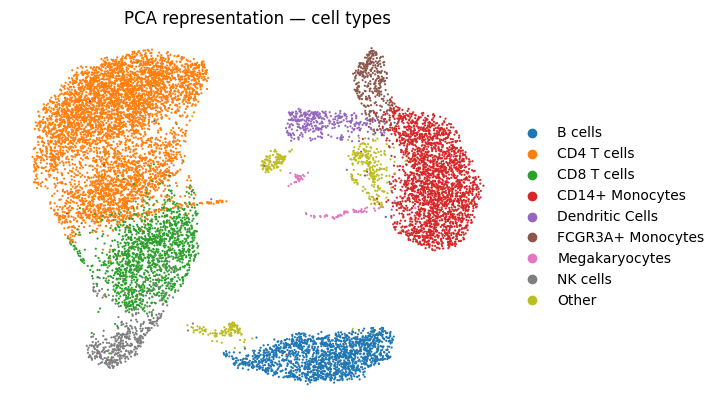

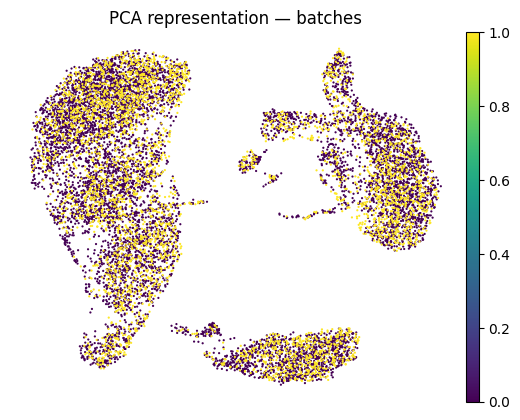

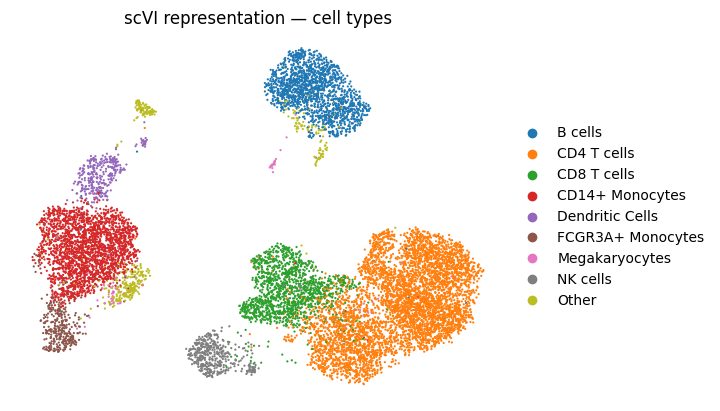

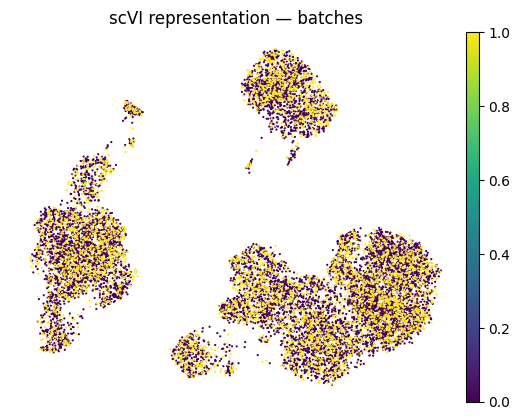

In [10]:
def save_umap(coords_key, colour_key, title, filename):
    old = adata.obsm["X_umap"].copy()
    adata.obsm["X_umap"] = adata.obsm[coords_key].copy()

    sc.pl.umap(
        adata,
        color=colour_key,
        title=title,
        show=False,
        frameon=False,
    )
    plt.savefig(
        RESULTS_DIR / filename,
        dpi=180,
        bbox_inches="tight",
    )
    plt.show()
    plt.close()

    adata.obsm["X_umap"] = old


save_umap(
    "X_umap_pca",
    "str_labels",
    "PCA representation — cell types",
    "umap_pca_cell_types.png",
)

save_umap(
    "X_umap_pca",
    "batch",
    "PCA representation — batches",
    "umap_pca_batch.png",
)

save_umap(
    "X_umap_scvi",
    "str_labels",
    "scVI representation — cell types",
    "umap_scvi_cell_types.png",
)

save_umap(
    "X_umap_scvi",
    "batch",
    "scVI representation — batches",
    "umap_scvi_batch.png",
)

## Step 10 — Evaluation functions

### Biological structure
- **Cell-type silhouette:** higher is better.
- **5-fold kNN balanced accuracy:** higher is better.

### Batch structure
- **Global absolute batch silhouette:** closer to zero is better.
- **Within-cell-type absolute batch silhouette:** closer to zero is better.

The within-cell-type measure is useful because a global batch score can be confounded by genuine biological differences among cell types.

In [11]:
cell_types = adata.obs["str_labels"].astype(str).to_numpy()
batches = adata.obs["batch"].astype(str).to_numpy()

def sampled_silhouette(X, labels, max_n=5000):
    n = len(labels)
    sample_size = min(max_n, n)
    return silhouette_score(
        X,
        labels,
        metric="euclidean",
        sample_size=sample_size if sample_size < n else None,
        random_state=SEED if sample_size < n else None,
    )

def knn_cv_balanced_accuracy(X, y, n_splits=5):
    cv = StratifiedKFold(
        n_splits=n_splits,
        shuffle=True,
        random_state=SEED,
    )

    scores = []
    for train_idx, test_idx in cv.split(X, y):
        clf = KNeighborsClassifier(n_neighbors=15)
        clf.fit(X[train_idx], y[train_idx])
        pred = clf.predict(X[test_idx])
        scores.append(
            balanced_accuracy_score(y[test_idx], pred)
        )

    return float(np.mean(scores)), float(np.std(scores))

def within_celltype_batch_silhouette(X, cell_labels, batch_labels):
    rows = []

    for cell_type in np.unique(cell_labels):
        idx = np.where(cell_labels == cell_type)[0]

        if len(idx) < 20:
            continue

        b = batch_labels[idx]

        if len(np.unique(b)) < 2:
            continue

        Xi = X[idx]
        n = len(idx)
        sample_size = min(2000, n)

        score = silhouette_score(
            Xi,
            b,
            metric="euclidean",
            sample_size=sample_size if sample_size < n else None,
            random_state=SEED if sample_size < n else None,
        )

        rows.append({
            "cell_type": cell_type,
            "n_cells": n,
            "abs_batch_silhouette": abs(score),
        })

    detail = pd.DataFrame(rows)

    weighted = np.average(
        detail["abs_batch_silhouette"],
        weights=detail["n_cells"],
    )

    return float(weighted), detail

## Step 11 — Compare PCA and scVI

In [12]:
rows = []
batch_detail_frames = []

for name, key in [
    ("PCA", "X_pca"),
    ("scVI", "X_scVI"),
]:
    X = np.asarray(adata.obsm[key])

    cell_sil = sampled_silhouette(
        X,
        cell_types,
        max_n=5000,
    )

    global_batch_sil = sampled_silhouette(
        X,
        batches,
        max_n=5000,
    )

    knn_mean, knn_sd = knn_cv_balanced_accuracy(
        X,
        cell_types,
        n_splits=5,
    )

    within_batch_sil, detail = within_celltype_batch_silhouette(
        X,
        cell_types,
        batches,
    )

    detail["representation"] = name
    batch_detail_frames.append(detail)

    rows.append({
        "representation": name,
        "cell_type_silhouette_higher_better": cell_sil,
        "global_abs_batch_silhouette_lower_better": abs(global_batch_sil),
        "within_celltype_abs_batch_silhouette_lower_better": within_batch_sil,
        "knn_balanced_accuracy_mean_higher_better": knn_mean,
        "knn_balanced_accuracy_sd": knn_sd,
    })

metrics = pd.DataFrame(rows)
batch_detail = pd.concat(batch_detail_frames, ignore_index=True)

metrics.to_csv(
    RESULTS_DIR / "representation_metrics.csv",
    index=False,
)

batch_detail.to_csv(
    RESULTS_DIR / "batch_mixing_by_cell_type.csv",
    index=False,
)

metrics

,representation,cell_type_silhouette_higher_better,global_abs_batch_silhouette_lower_better,within_celltype_abs_batch_silhouette_lower_better,knn_balanced_accuracy_mean_higher_better,knn_balanced_accuracy_sd
0,PCA,0.399148,0.006007,0.010235,0.941734,0.015866
1,scVI,0.208445,0.004948,0.003944,0.884385,0.012327


## Step 12 — Inspect batch mixing by cell type

In [13]:
batch_detail.sort_values(
    ["cell_type", "representation"]
)

,cell_type,n_cells,abs_batch_silhouette,representation
0,B cells,1621,0.007019,PCA
9,B cells,1621,0.004709,scVI
1,CD14+ Monocytes,2227,0.016276,PCA
10,CD14+ Monocytes,2227,0.007476,scVI
2,CD4 T cells,4996,0.005089,PCA
11,CD4 T cells,4996,0.000950,scVI
3,CD8 T cells,1448,0.004278,PCA
12,CD8 T cells,1448,0.001432,scVI
4,Dendritic Cells,339,0.035346,PCA
13,Dendritic Cells,339,0.015566,scVI


## Step 13 — Save training history and software versions

In [14]:
history_frames = []

for name, values in model.history.items():
    temp = values.copy().reset_index()
    temp["metric"] = name
    history_frames.append(temp)

if history_frames:
    training_history = pd.concat(
        history_frames,
        ignore_index=True,
    )
    training_history.to_csv(
        RESULTS_DIR / "training_history.csv",
        index=False,
    )

versions = {
    "python": os.sys.version.split()[0],
    "scvi-tools": scvi.__version__,
    "scanpy": importlib_metadata.version("scanpy"),
    "torch": torch.__version__,
    "numpy": np.__version__,
    "pandas": pd.__version__,
}

pd.DataFrame(
    list(versions.items()),
    columns=["package", "version"],
).to_csv(
    RESULTS_DIR / "software_versions.csv",
    index=False,
)

print(pd.DataFrame(list(versions.items()), columns=["package", "version"]))

      package       version
0      python       3.13.15
1  scvi-tools         1.5.1
2      scanpy        1.12.4
3       torch  2.11.0+cu130
4       numpy         2.1.3
5      pandas         3.0.6


## Step 14 — Final metric table

Send this table to ChatGPT together with the final ZIP file.

In [15]:
pd.set_option("display.max_columns", None)
metrics

,representation,cell_type_silhouette_higher_better,global_abs_batch_silhouette_lower_better,within_celltype_abs_batch_silhouette_lower_better,knn_balanced_accuracy_mean_higher_better,knn_balanced_accuracy_sd
0,PCA,0.399148,0.006007,0.010235,0.941734,0.015866
1,scVI,0.208445,0.004948,0.003944,0.884385,0.012327


## Step 15 — Create the final results ZIP

In [16]:
zip_path = Path("deborah_single_cell_final_results.zip")

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zf:
    for path in RESULTS_DIR.rglob("*"):
        if path.is_file():
            zf.write(
                path,
                arcname=path.relative_to(RESULTS_DIR.parent),
            )

print(f"Created: {zip_path.resolve()}")
print("\nFiles included:")

for path in sorted(RESULTS_DIR.iterdir()):
    if path.is_file():
        print(" -", path.name)

Created: /content/deborah_single_cell_final_results.zip

Files included:
 - batch_mixing_by_cell_type.csv
 - representation_metrics.csv
 - scvi_training_curve.png
 - software_versions.csv
 - training_history.csv
 - umap_pca_batch.png
 - umap_pca_cell_types.png
 - umap_scvi_batch.png
 - umap_scvi_cell_types.png


# Finished

Download `deborah_single_cell_final_results.zip` from the Colab Files panel and send it back.

After that we will:
1. interpret the final results carefully;
2. write the GitHub README using only the results the analysis supports;
3. clean and publish the repository;
4. add a concise, truthful project entry to the CV;
5. use the project appropriately in the Basel motivation letter.